In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import duckdb
import joblib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

REPORT_DIR = ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

REPORT_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


In [3]:
MODEL_PATH = ROOT / "models" / "lightgbm_model.joblib"

assert MODEL_PATH.exists(), (
    "Saved model missing. Run the Day 6 model-saving cell."
)

saved = joblib.load(MODEL_PATH)

model = saved["model"]
preprocessor = saved["preprocessor"]
features = saved["features"]

print("Model:", type(model).__name__)
print("Original features:", len(features))
print("Best iteration:", model.best_iteration_)

Model: LGBMClassifier
Original features: 27
Best iteration: 524


In [4]:
DATA_PATH = (
    ROOT / "data" / "processed" /
    "modeling_features.parquet"
)

con = duckdb.connect()

df = con.execute(
    "SELECT * FROM read_parquet(?)",
    [str(DATA_PATH)]
).df()

assert len(df) == 307511
assert df["SK_ID_CURR"].is_unique

X = df[features].copy()
y = df["TARGET"].astype(int)

numeric_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

X[numeric_cols] = X[numeric_cols].replace(
    [np.inf, -np.inf], np.nan
)

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev,
    test_size=0.25,
    stratify=y_dev,
    random_state=42
)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Held-out test:", len(X_test))

Training: 184506
Validation: 61502
Held-out test: 61503


In [5]:
X_val_processed = preprocessor.transform(X_val)

val_probabilities = model.predict_proba(
    X_val_processed
)[:, 1]

print(
    "Validation ROC-AUC:",
    round(roc_auc_score(y_val, val_probabilities), 4)
)

print(
    "Validation Average Precision:",
    round(
        average_precision_score(y_val, val_probabilities),
        4
    )
)

/Users/preeyapat/miniconda3/envs/homecredit/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Validation ROC-AUC: 0.7541
Validation Average Precision: 0.2373


In [6]:
risk_df = pd.DataFrame({
    "SK_ID_CURR": df.loc[X_val.index, "SK_ID_CURR"].to_numpy(),
    "Actual_Target": y_val.to_numpy(),
    "Predicted_Risk": val_probabilities,
    "Income": X_val["AMT_INCOME_TOTAL"].to_numpy(),
    "Credit": X_val["AMT_CREDIT"].to_numpy(),
    "Annuity": X_val["AMT_ANNUITY"].to_numpy(),
    "Credit_Income_Ratio": X_val[
        "credit_income_ratio"
    ].to_numpy(),
    "Annuity_Income_Ratio": X_val[
        "annuity_income_ratio"
    ].to_numpy(),
    "Has_Bureau_History": X_val[
        "has_bureau_history"
    ].to_numpy()
})

assert risk_df["SK_ID_CURR"].is_unique
assert len(risk_df) == len(X_val)
assert risk_df["Actual_Target"].mean() > 0

display(risk_df.head())

,SK_ID_CURR,Actual_Target,Predicted_Risk,Income,Credit,Annuity,Credit_Income_Ratio,Annuity_Income_Ratio,Has_Bureau_History
0,266566,0,0.050443,162000.0,900000.0,45954.0,5.555556,0.283667,1
1,213937,0,0.028684,81000.0,625536.0,22599.0,7.722667,0.279000,1
2,282674,0,0.034350,90000.0,675000.0,28507.5,7.500000,0.316750,1
3,304801,0,0.055259,112500.0,1125000.0,33025.5,10.000000,0.293560,1
4,166265,0,0.039579,90000.0,900000.0,26446.5,10.000000,0.293850,1


In [7]:
risk_df["Risk_Decile"] = pd.qcut(
    risk_df["Predicted_Risk"].rank(method="first"),
    q=10,
    labels=False
) + 1

print(risk_df["Risk_Decile"].value_counts().sort_index())

Risk_Decile
1     6151
2     6150
3     6150
4     6150
5     6150
6     6150
7     6150
8     6150
9     6150
10    6151
Name: count, dtype: int64


In [8]:
overall_rate = risk_df["Actual_Target"].mean()
total_positives = risk_df["Actual_Target"].sum()

decile_summary = (
    risk_df.groupby("Risk_Decile")
    .agg(
        Applicants=("Actual_Target", "size"),
        Positive_Cases=("Actual_Target", "sum"),
        Observed_Rate=("Actual_Target", "mean"),
        Mean_Predicted_Risk=("Predicted_Risk", "mean"),
        Min_Predicted_Risk=("Predicted_Risk", "min"),
        Max_Predicted_Risk=("Predicted_Risk", "max")
    )
    .reset_index()
)

decile_summary["Lift"] = (
    decile_summary["Observed_Rate"] / overall_rate
)

decile_summary["Share_of_All_Positives"] = (
    decile_summary["Positive_Cases"] / total_positives
)

display(decile_summary.round(4))

,Risk_Decile,Applicants,Positive_Cases,Observed_Rate,Mean_Predicted_Risk,Min_Predicted_Risk,Max_Predicted_Risk,Lift,Share_of_All_Positives
0,1,6151,97,0.0158,0.0151,0.0031,0.0196,0.1953,0.0195
1,2,6150,117,0.0190,0.0232,0.0196,0.0266,0.2357,0.0236
2,3,6150,181,0.0294,0.0303,0.0266,0.0340,0.3646,0.0365
3,4,6150,231,0.0376,0.0383,0.0340,0.0429,0.4653,0.0465
4,5,6150,302,0.0491,0.0482,0.0429,0.0540,0.6083,0.0608
5,6,6150,340,0.0553,0.0608,0.0540,0.0683,0.6848,0.0685
6,7,6150,482,0.0784,0.0779,0.0683,0.0885,0.9708,0.0971
7,8,6150,643,0.1046,0.1024,0.0885,0.1189,1.2951,0.1295
8,9,6150,903,0.1468,0.1455,0.1189,0.1804,1.8188,0.1819
9,10,6151,1669,0.2713,0.2699,0.1804,0.7661,3.3611,0.3362


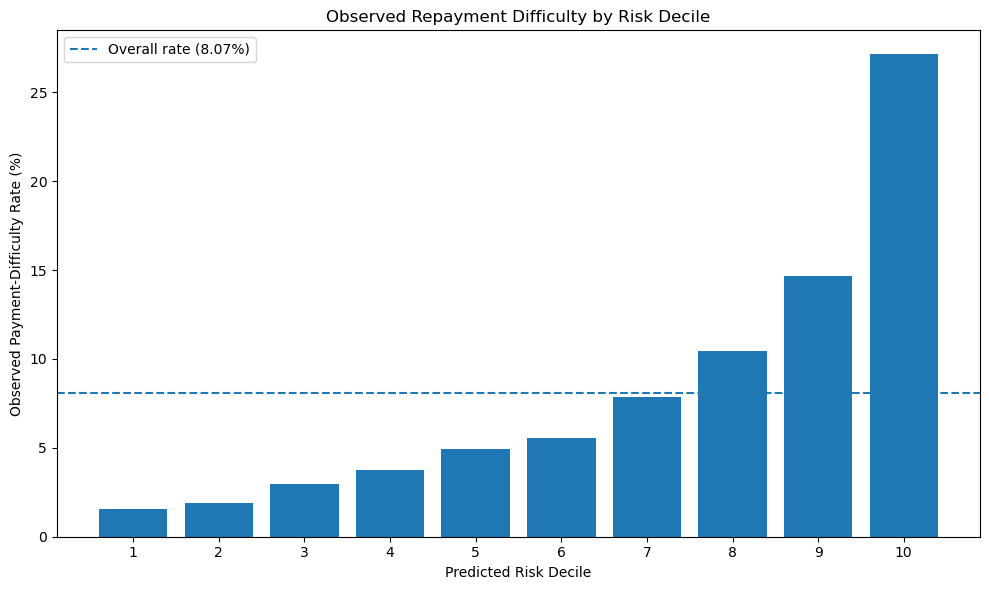

In [9]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    decile_summary["Risk_Decile"],
    decile_summary["Observed_Rate"] * 100
)

ax.axhline(
    overall_rate * 100,
    linestyle="--",
    label=f"Overall rate ({overall_rate:.2%})"
)

ax.set_xlabel("Predicted Risk Decile")
ax.set_ylabel("Observed Payment-Difficulty Rate (%)")
ax.set_title("Observed Repayment Difficulty by Risk Decile")
ax.set_xticks(range(1, 11))
ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "day09_observed_risk_by_decile.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

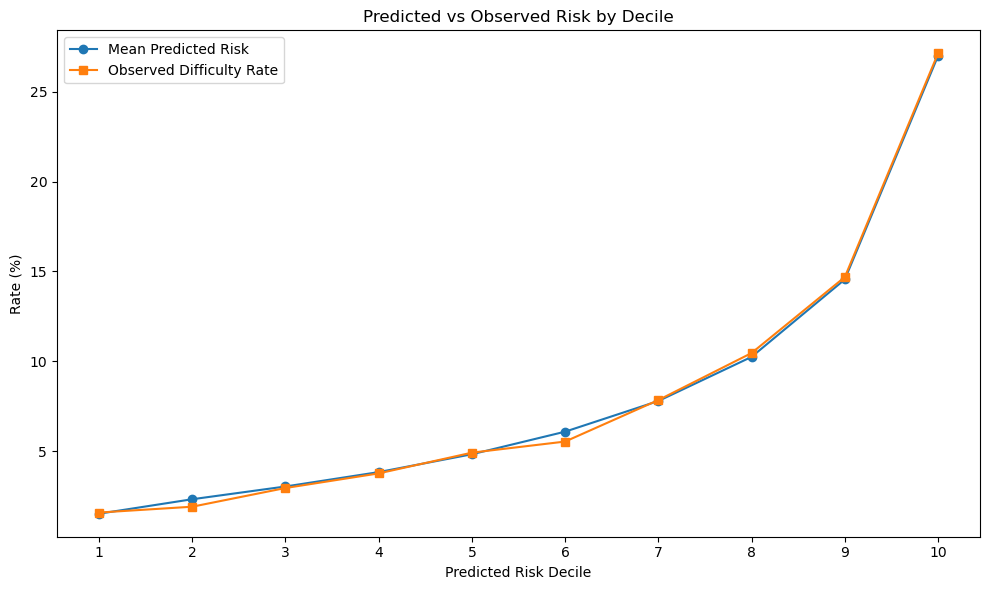

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    decile_summary["Risk_Decile"],
    decile_summary["Mean_Predicted_Risk"] * 100,
    marker="o",
    label="Mean Predicted Risk"
)

ax.plot(
    decile_summary["Risk_Decile"],
    decile_summary["Observed_Rate"] * 100,
    marker="s",
    label="Observed Difficulty Rate"
)

ax.set_xlabel("Predicted Risk Decile")
ax.set_ylabel("Rate (%)")
ax.set_title("Predicted vs Observed Risk by Decile")
ax.set_xticks(range(1, 11))
ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "day09_predicted_vs_observed.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [11]:
capture_df = (
    decile_summary
    .sort_values("Risk_Decile", ascending=False)
    .copy()
)

capture_df["Cumulative_Applicants"] = (
    capture_df["Applicants"].cumsum()
)

capture_df["Cumulative_Positives"] = (
    capture_df["Positive_Cases"].cumsum()
)

capture_df["Population_Share"] = (
    capture_df["Cumulative_Applicants"] / len(risk_df)
)

capture_df["Capture_Rate"] = (
    capture_df["Cumulative_Positives"] / total_positives
)

capture_df["Cumulative_Lift"] = (
    capture_df["Capture_Rate"] /
    capture_df["Population_Share"]
)

display(
    capture_df[
        [
            "Risk_Decile",
            "Population_Share",
            "Capture_Rate",
            "Cumulative_Lift"
        ]
    ].round(4)
)

,Risk_Decile,Population_Share,Capture_Rate,Cumulative_Lift
9,10,0.1,0.3362,3.3611
8,9,0.2,0.5180,2.5900
7,8,0.3,0.6475,2.1584
6,7,0.4,0.7446,1.8615
5,6,0.5,0.8131,1.6262
4,5,0.6,0.8739,1.4565
3,4,0.7,0.9204,1.3149
2,3,0.8,0.9569,1.1961
1,2,0.9,0.9805,1.0894
0,1,1.0,1.0000,1.0000


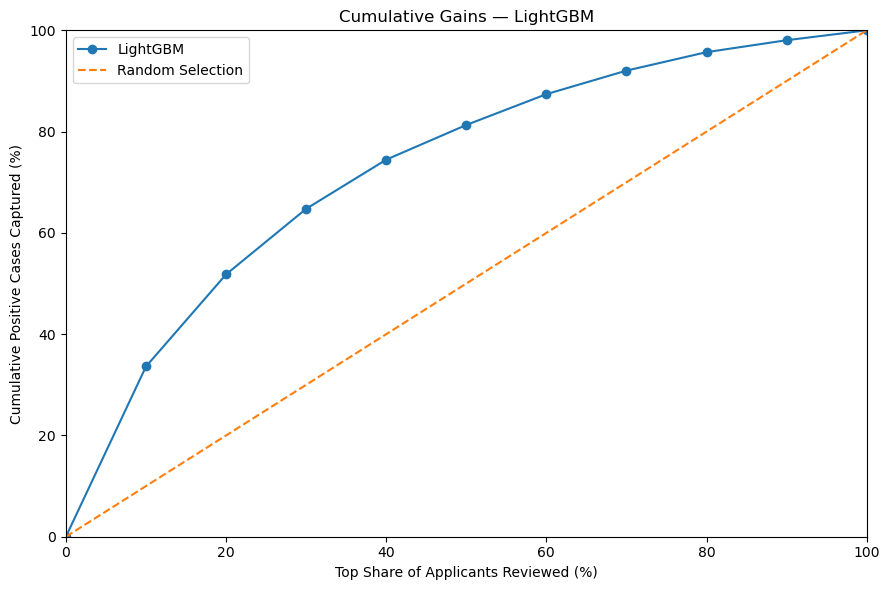

In [12]:
plot_df = capture_df.sort_values("Population_Share")

x = np.concatenate([
    [0],
    plot_df["Population_Share"].to_numpy()
])

y = np.concatenate([
    [0],
    plot_df["Capture_Rate"].to_numpy()
])

fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    x * 100,
    y * 100,
    marker="o",
    label="LightGBM"
)

ax.plot(
    [0, 100],
    [0, 100],
    "--",
    label="Random Selection"
)

ax.set_xlabel("Top Share of Applicants Reviewed (%)")
ax.set_ylabel("Cumulative Positive Cases Captured (%)")
ax.set_title("Cumulative Gains — LightGBM")
ax.legend()
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "day09_cumulative_gains.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [13]:
capacity_table = capture_df[
    [
        "Population_Share",
        "Cumulative_Applicants",
        "Cumulative_Positives",
        "Capture_Rate",
        "Cumulative_Lift"
    ]
].copy()

capacity_table["Population_Share"] *= 100
capacity_table["Capture_Rate"] *= 100

capacity_table = capacity_table.rename(columns={
    "Population_Share": "Review Capacity (%)",
    "Cumulative_Applicants": "Applicants Reviewed",
    "Cumulative_Positives": "Positive Cases Captured",
    "Capture_Rate": "Recall (%)",
    "Cumulative_Lift": "Cumulative Lift"
})

display(capacity_table.round(2))

,Review Capacity (%),Applicants Reviewed,Positive Cases Captured,Recall (%),Cumulative Lift
9,10.0,6151,1669,33.62,3.36
8,20.0,12301,2572,51.80,2.59
7,30.0,18451,3215,64.75,2.16
6,40.0,24601,3697,74.46,1.86
5,50.0,30751,4037,81.31,1.63
4,60.0,36901,4339,87.39,1.46
3,70.0,43051,4570,92.04,1.31
2,80.0,49201,4751,95.69,1.20
1,90.0,55351,4868,98.05,1.09
0,100.0,61502,4965,100.00,1.00


In [14]:
def create_quintiles(series):
    result = pd.Series(
        pd.NA,
        index=series.index,
        dtype="Int64"
    )

    valid = series.notna() & np.isfinite(series)

    if valid.sum() >= 5:
        result.loc[valid] = (
            pd.qcut(
                series.loc[valid].rank(method="first"),
                q=5,
                labels=False
            ).astype(int) + 1
        ).to_numpy()

    return result


risk_df["Income_Quintile"] = create_quintiles(
    risk_df["Income"]
)

risk_df["Annuity_Burden_Quintile"] = create_quintiles(
    risk_df["Annuity_Income_Ratio"]
)

risk_df["Bureau_Group"] = np.where(
    risk_df["Has_Bureau_History"] == 1,
    "Has Bureau History",
    "No Bureau History"
)

display(
    risk_df[
        [
            "Income_Quintile",
            "Annuity_Burden_Quintile",
            "Bureau_Group"
        ]
    ].head()
)

,Income_Quintile,Annuity_Burden_Quintile,Bureau_Group
0,3,5,Has Bureau History
1,1,5,Has Bureau History
2,1,5,Has Bureau History
3,2,5,Has Bureau History
4,1,5,Has Bureau History


In [15]:
def analyze_segments(data, group_column):
    rows = []

    for group_name, group in data.groupby(
        group_column, dropna=False
    ):
        y_true = group["Actual_Target"]
        probabilities = group["Predicted_Risk"]

        result = {
            "Segment": str(group_name),
            "Applicants": len(group),
            "Positive_Cases": int(y_true.sum()),
            "Observed_Rate": y_true.mean(),
            "Mean_Predicted_Risk": probabilities.mean(),
            "Brier_Score": brier_score_loss(
                y_true, probabilities
            )
        }

        if y_true.nunique() == 2:
            result["ROC_AUC"] = roc_auc_score(
                y_true, probabilities
            )
            result["Average_Precision"] = (
                average_precision_score(
                    y_true, probabilities
                )
            )
        else:
            result["ROC_AUC"] = np.nan
            result["Average_Precision"] = np.nan

        rows.append(result)

    return pd.DataFrame(rows)

In [16]:
income_segments = analyze_segments(
    risk_df,
    "Income_Quintile"
)

display(income_segments.round(4))

,Segment,Applicants,Positive_Cases,Observed_Rate,Mean_Predicted_Risk,Brier_Score,ROC_AUC,Average_Precision
0,1,12301,1006,0.0818,0.0812,0.0689,0.7522,0.2390
1,2,12300,1081,0.0879,0.0867,0.0727,0.7568,0.2651
2,3,12300,1052,0.0855,0.0875,0.0725,0.7369,0.2358
3,4,12300,1038,0.0844,0.0817,0.0700,0.7645,0.2550
4,5,12301,788,0.0641,0.0688,0.0562,0.7520,0.1883


In [17]:
burden_segments = analyze_segments(
    risk_df,
    "Annuity_Burden_Quintile"
)

display(burden_segments.round(4))

,Segment,Applicants,Positive_Cases,Observed_Rate,Mean_Predicted_Risk,Brier_Score,ROC_AUC,Average_Precision
0,1,12300,825,0.0671,0.0724,0.0587,0.7456,0.1887
1,2,12300,960,0.0780,0.0778,0.0661,0.7646,0.2293
2,3,12300,1038,0.0844,0.0831,0.0710,0.7455,0.2432
3,4,12300,1076,0.0875,0.0874,0.0720,0.7631,0.2720
4,5,12300,1066,0.0867,0.0851,0.0726,0.7464,0.2448
5,<NA>,2,0,0.0000,0.0912,0.0088,NaN,NaN


In [18]:
bureau_segments = analyze_segments(
    risk_df,
    "Bureau_Group"
)

display(bureau_segments.round(4))

,Segment,Applicants,Positive_Cases,Observed_Rate,Mean_Predicted_Risk,Brier_Score,ROC_AUC,Average_Precision
0,Has Bureau History,52694,4059,0.0770,0.0777,0.0650,0.7590,0.2380
1,No Bureau History,8808,906,0.1029,0.1017,0.0865,0.7119,0.2349


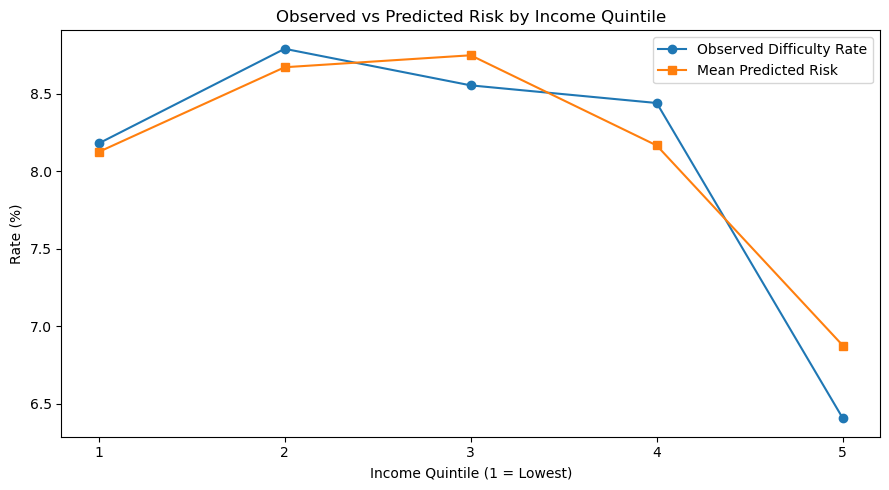

In [19]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    income_segments["Segment"],
    income_segments["Observed_Rate"] * 100,
    marker="o",
    label="Observed Difficulty Rate"
)

ax.plot(
    income_segments["Segment"],
    income_segments["Mean_Predicted_Risk"] * 100,
    marker="s",
    label="Mean Predicted Risk"
)

ax.set_title("Observed vs Predicted Risk by Income Quintile")
ax.set_xlabel("Income Quintile (1 = Lowest)")
ax.set_ylabel("Rate (%)")
ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "day09_income_segments.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

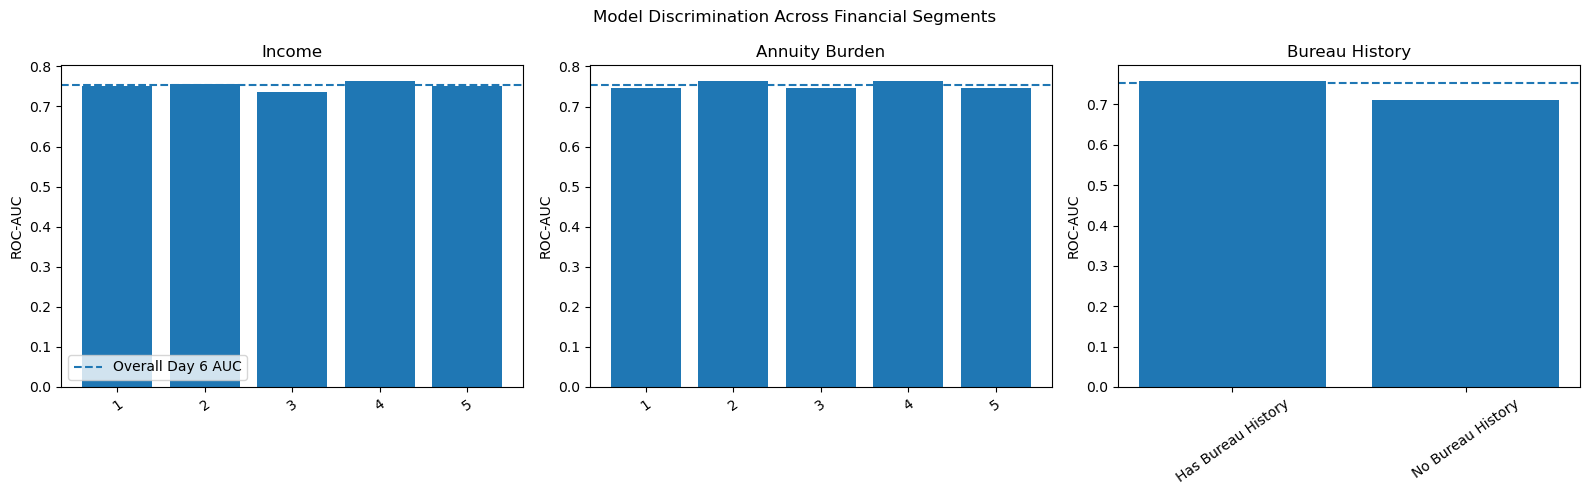

In [20]:
segment_tables = {
    "Income": income_segments,
    "Annuity Burden": burden_segments,
    "Bureau History": bureau_segments
}

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, table) in zip(
    axes, segment_tables.items()
):
    ax.bar(
        table["Segment"],
        table["ROC_AUC"]
    )

    ax.axhline(
        0.7541,
        linestyle="--",
        label="Overall Day 6 AUC"
    )

    ax.set_title(name)
    ax.set_ylabel("ROC-AUC")
    ax.tick_params(
        axis="x",
        rotation=35
    )

axes[0].legend()

plt.suptitle("Model Discrimination Across Financial Segments")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "day09_segment_performance.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [21]:
from statsmodels.stats.proportion import proportion_confint

lower, upper = proportion_confint(
    count=decile_summary["Positive_Cases"].to_numpy(),
    nobs=decile_summary["Applicants"].to_numpy(),
    alpha=0.05,
    method="wilson"
)

decile_summary["Rate_CI_Lower"] = lower
decile_summary["Rate_CI_Upper"] = upper

display(
    decile_summary[
        [
            "Risk_Decile",
            "Observed_Rate",
            "Rate_CI_Lower",
            "Rate_CI_Upper"
        ]
    ].round(4)
)

,Risk_Decile,Observed_Rate,Rate_CI_Lower,Rate_CI_Upper
0,1,0.0158,0.0129,0.0192
1,2,0.0190,0.0159,0.0228
2,3,0.0294,0.0255,0.0340
3,4,0.0376,0.0331,0.0426
4,5,0.0491,0.0440,0.0548
5,6,0.0553,0.0498,0.0613
6,7,0.0784,0.0719,0.0854
7,8,0.1046,0.0972,0.1124
8,9,0.1468,0.1382,0.1559
9,10,0.2713,0.2604,0.2826


In [22]:
decile_summary.to_csv(
    REPORT_DIR / "day09_risk_deciles.csv",
    index=False
)

capacity_table.to_csv(
    REPORT_DIR / "day09_capture_analysis.csv",
    index=False
)

income_segments.to_csv(
    REPORT_DIR / "day09_income_segments.csv",
    index=False
)

burden_segments.to_csv(
    REPORT_DIR / "day09_annuity_burden_segments.csv",
    index=False
)

bureau_segments.to_csv(
    REPORT_DIR / "day09_bureau_segments.csv",
    index=False
)

print("Dashboard-ready Day 9 aggregate tables saved.")

Dashboard-ready Day 9 aggregate tables saved.
